In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

Note: you may need to restart the kernel to use updated packages.


In [ ]:
from src.data import load_competition_data

train, test = load_competition_data()

train.head()

,id,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,0,15674932,Okwudilichukwu,668,France,Male,33.0,3,0.00,2,1.0,0.0,181449.97,0
1,1,15749177,Okwudiliolisa,627,France,Male,33.0,1,0.00,2,1.0,1.0,49503.50,0
2,2,15694510,Hsueh,678,France,Male,40.0,10,0.00,2,1.0,0.0,184866.69,0
3,3,15741417,Kao,581,France,Male,34.0,2,148882.54,1,1.0,1.0,84560.88,0
4,4,15766172,Chiemenam,716,Spain,Male,33.0,5,0.00,2,1.0,1.0,15068.83,0


In [4]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 165034 entries, 0 to 165033
Data columns (total 14 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   id               165034 non-null  int64  
 1   CustomerId       165034 non-null  int64  
 2   Surname          165034 non-null  str    
 3   CreditScore      165034 non-null  int64  
 4   Geography        165034 non-null  str    
 5   Gender           165034 non-null  str    
 6   Age              165034 non-null  float64
 7   Tenure           165034 non-null  int64  
 8   Balance          165034 non-null  float64
 9   NumOfProducts    165034 non-null  int64  
 10  HasCrCard        165034 non-null  float64
 11  IsActiveMember   165034 non-null  float64
 12  EstimatedSalary  165034 non-null  float64
 13  Exited           165034 non-null  int64  
dtypes: float64(5), int64(6), str(3)
memory usage: 17.6 MB


In [5]:
train.describe()

,id,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,165034.0000,1.650340e+05,165034.000000,165034.000000,165034.000000,165034.000000,165034.000000,165034.000000,165034.000000,165034.000000,165034.000000
mean,82516.5000,1.569201e+07,656.454373,38.125888,5.020353,55478.086689,1.554455,0.753954,0.497770,112574.822734,0.211599
std,47641.3565,7.139782e+04,80.103340,8.867205,2.806159,62817.663278,0.547154,0.430707,0.499997,50292.865585,0.408443
min,0.0000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.000000,0.000000,11.580000,0.000000
25%,41258.2500,1.563314e+07,597.000000,32.000000,3.000000,0.000000,1.000000,1.000000,0.000000,74637.570000,0.000000
50%,82516.5000,1.569017e+07,659.000000,37.000000,5.000000,0.000000,2.000000,1.000000,0.000000,117948.000000,0.000000
75%,123774.7500,1.575682e+07,710.000000,42.000000,7.000000,119939.517500,2.000000,1.000000,1.000000,155152.467500,0.000000
max,165033.0000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.000000,1.000000,199992.480000,1.000000


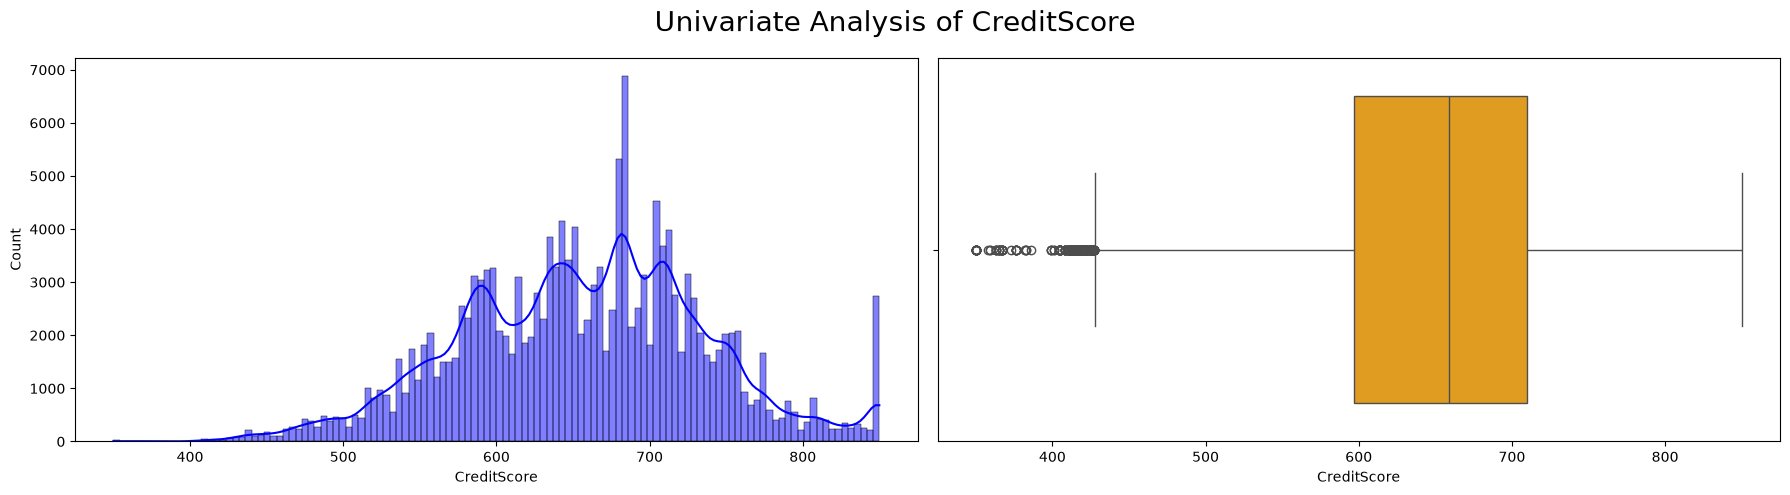

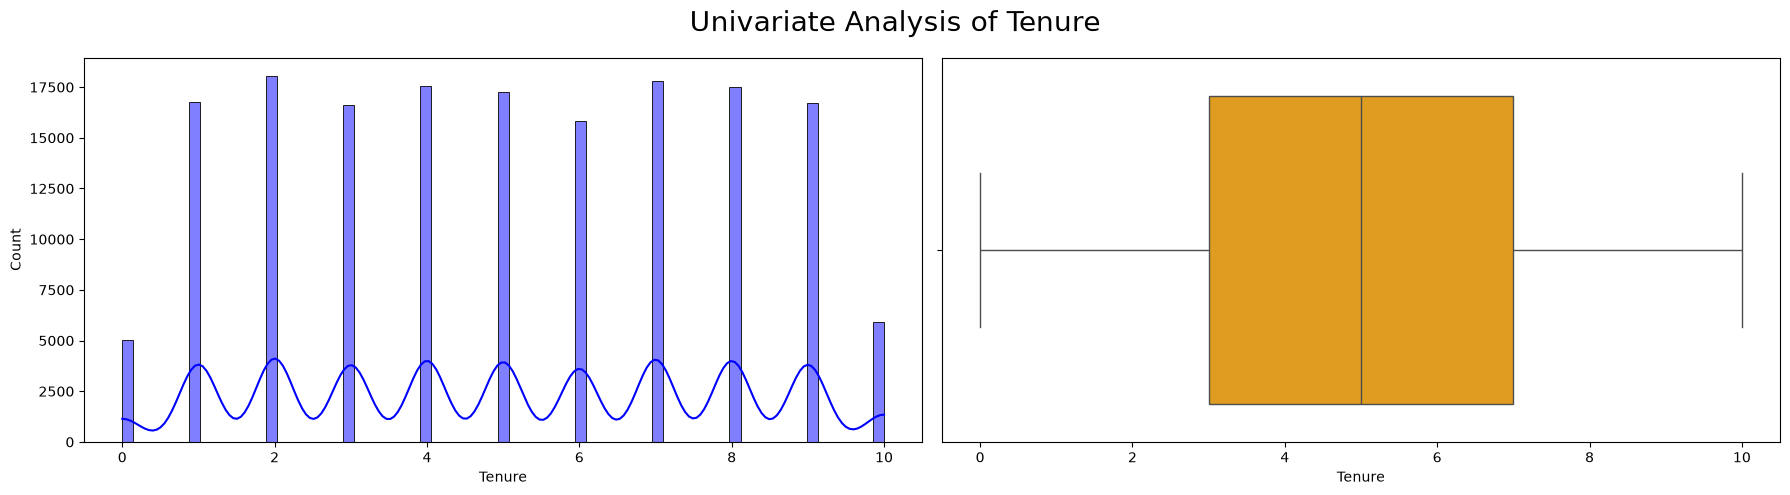

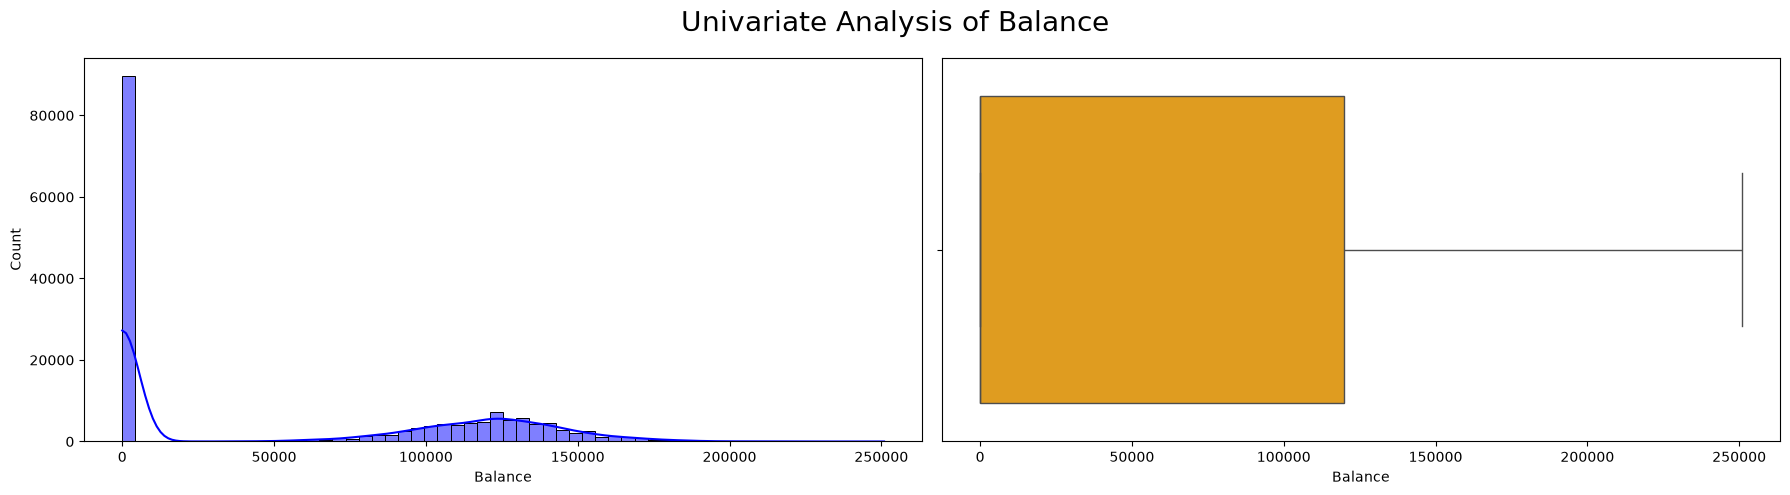

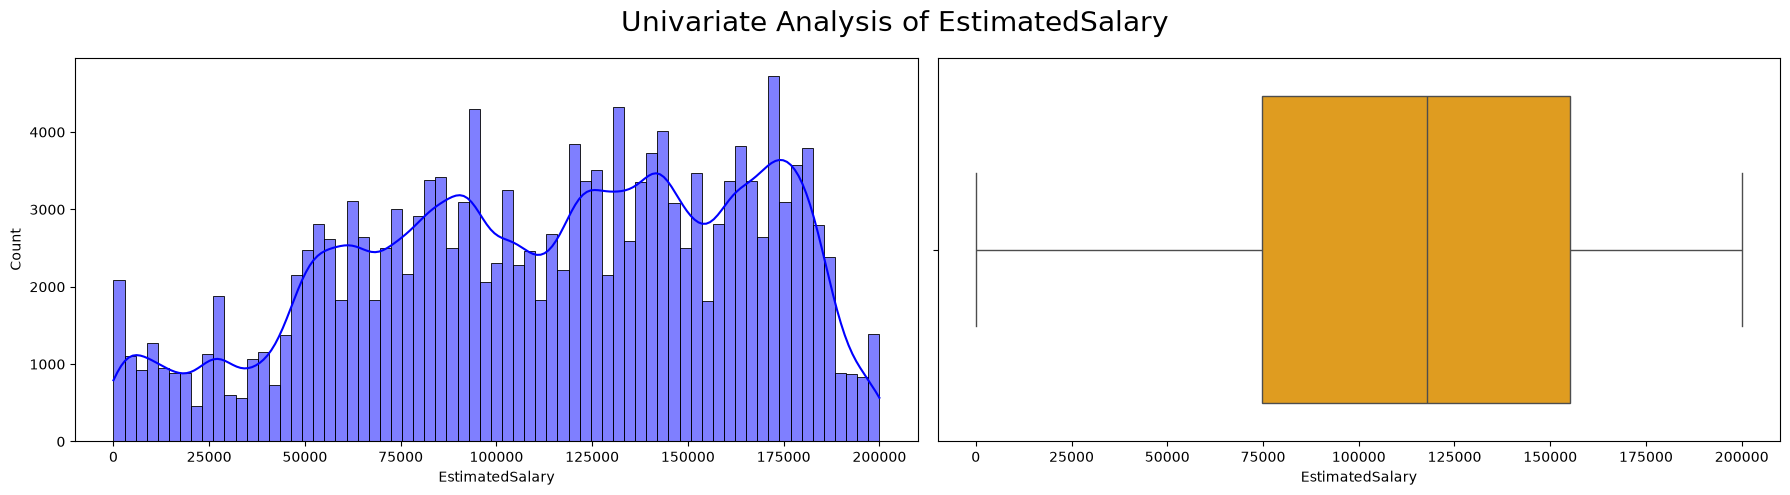

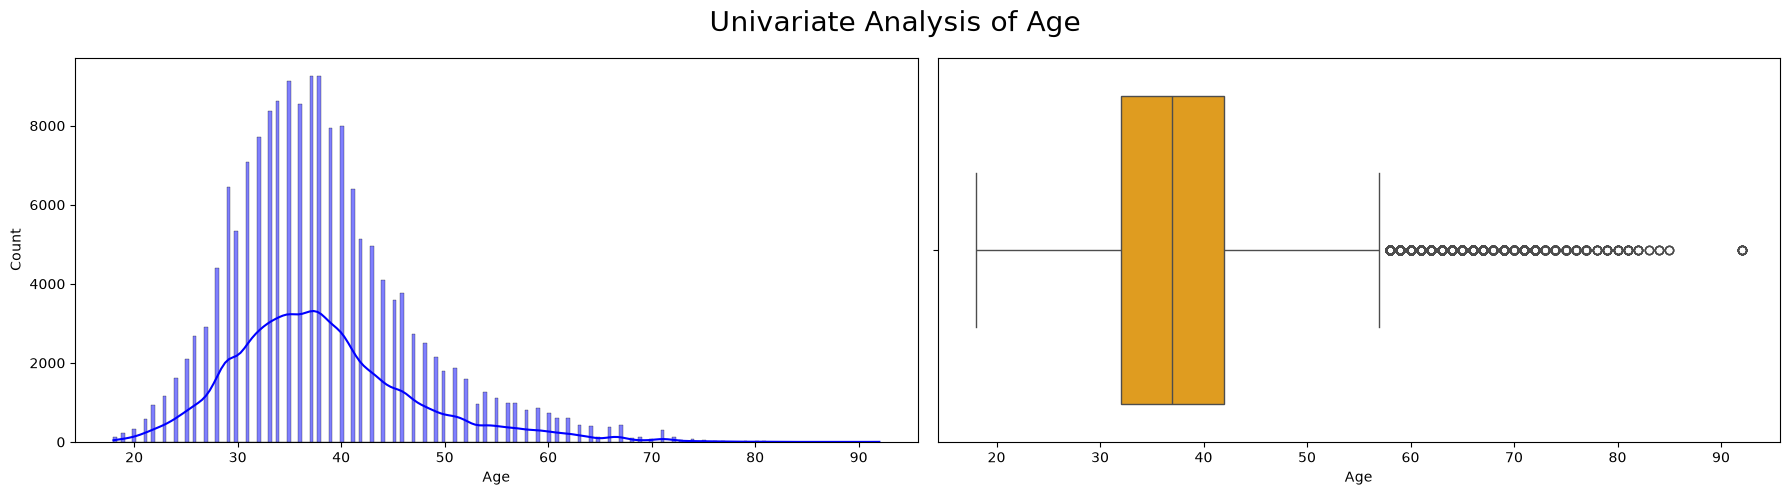

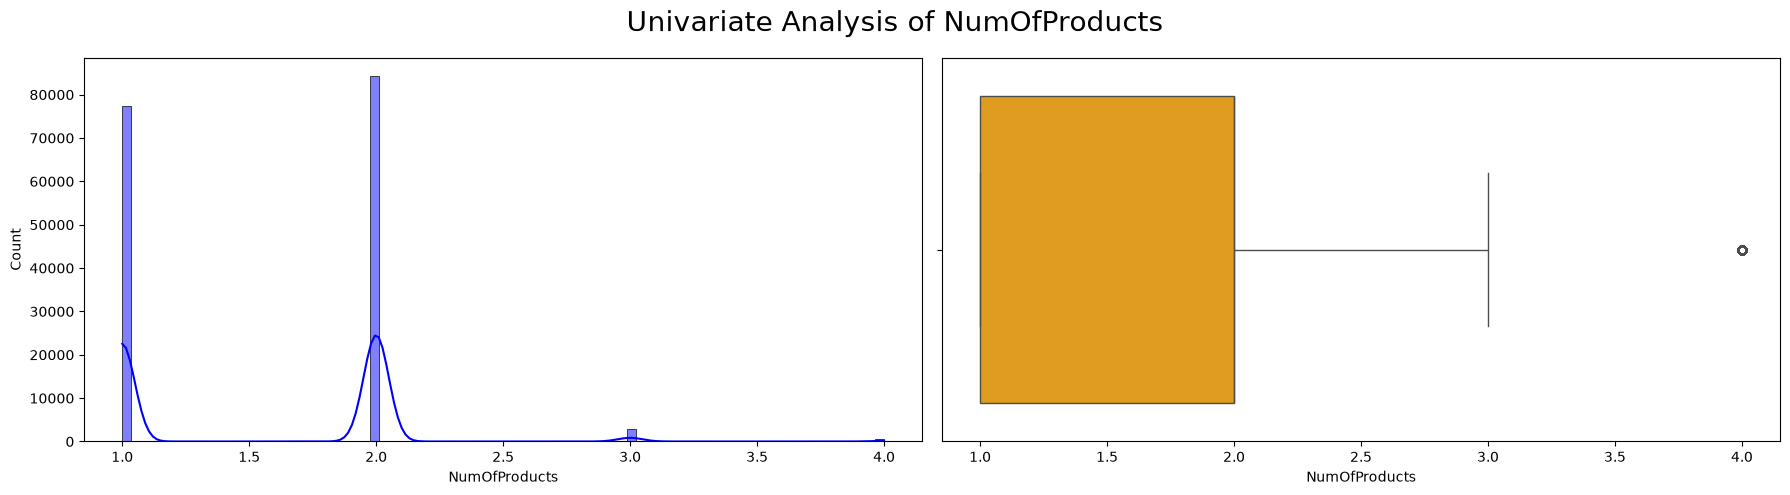

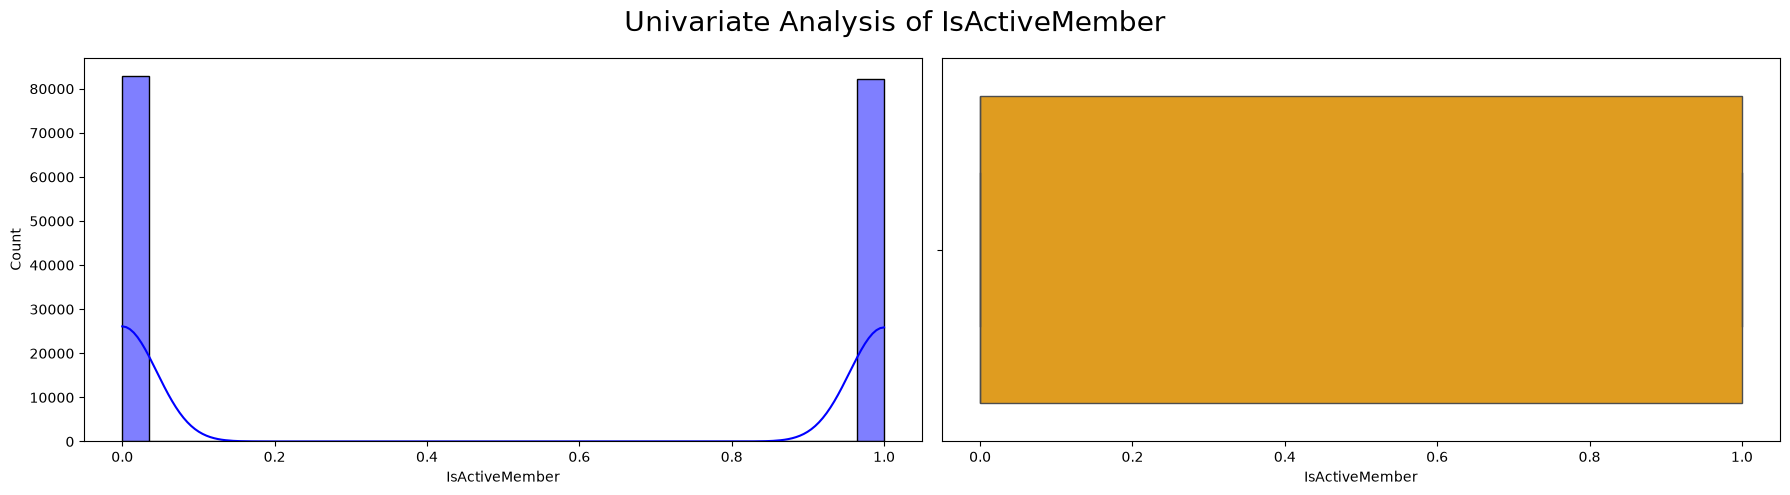

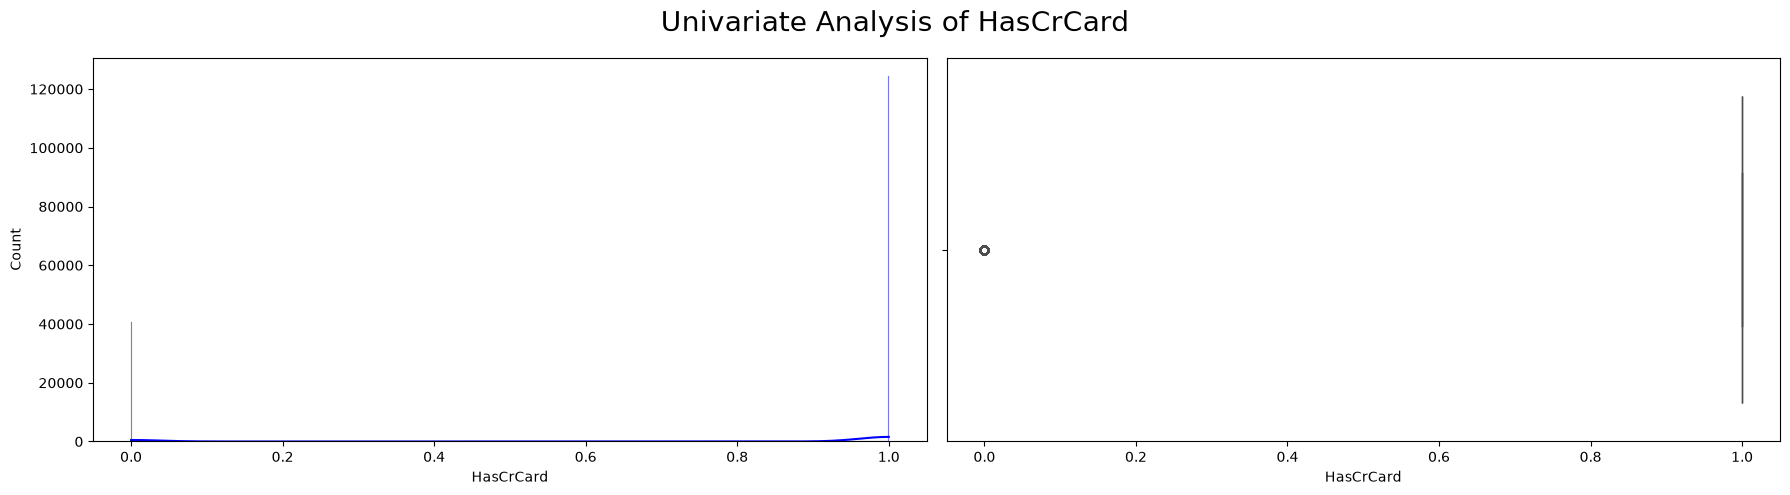

In [6]:
# Univariate Analysis

def outlier_check(columns, train_data):
    for column in columns:
        fig, axes  = plt.subplots(1,2,figsize=(18,5))
        fig.suptitle(f'Univariate Analysis of {column}', fontsize=20)
        sns.histplot(data=train_data, x=column, kde=True, ax=axes[0], color='blue')
        sns.boxplot(data=train_data, x=column, ax=axes[1], color='orange')
        plt.tight_layout()
        plt.show()



# columns to check for outliers
columns_to_check = ['CreditScore', 'Tenure', 'Balance', 'EstimatedSalary', 
                    'Age', 'NumOfProducts', 'IsActiveMember', 'HasCrCard']

outlier_check(columns_to_check, train)


c:\Users\aderinoye stephen\Desktop\playground-series-s4e1\.venv\Lib\site-packages\seaborn\axisgrid.py:718: UserWarning: Using the countplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)
c:\Users\aderinoye stephen\Desktop\playground-series-s4e1\.venv\Lib\site-packages\seaborn\axisgrid.py:854: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  func(*plot_args, **plot_kwargs)
c:\Users\aderinoye stephen\Desktop\playground-series-s4e1\.venv\Lib\site-packages\seaborn\axisgrid.py:854: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  func(*plot_args, **plot_kwargs)
c:\Users\aderinoye stephen\Desktop\playground-series-s4e1\.venv\Lib\site-packages\seaborn\axisgrid.py:854: Futu

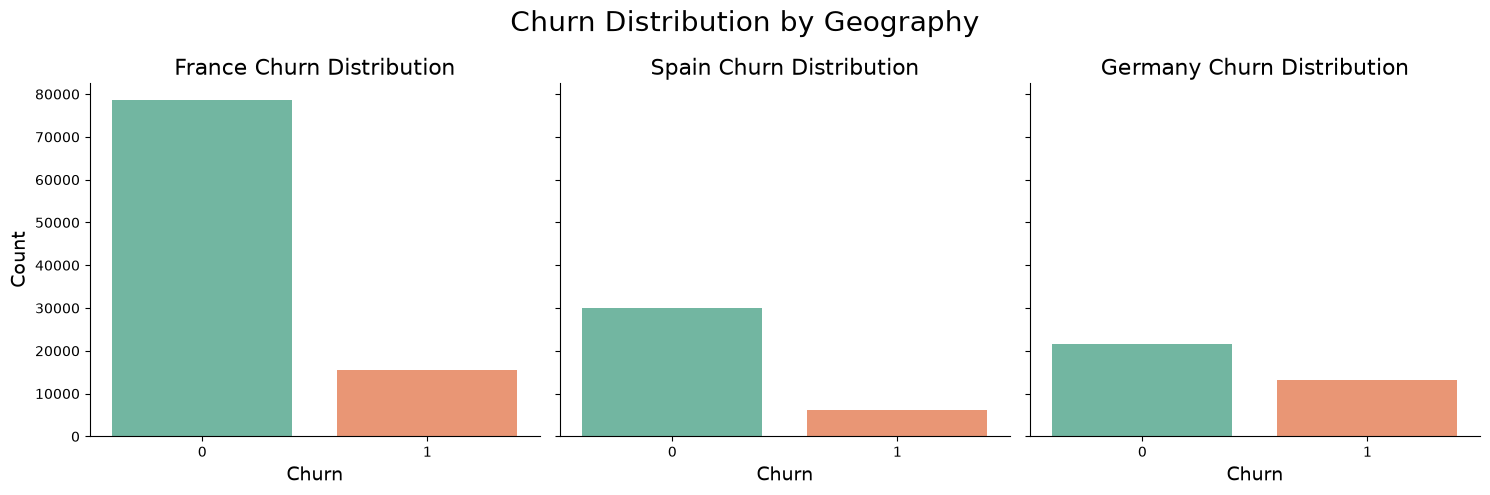

In [7]:
 # bivariate analysis 

# Churn distribution with respect to categorical features
# churn by Geography
g  = sns.FacetGrid(train, col='Geography', height=5, aspect=1)

g.map(sns.countplot, 'Exited', palette='Set2')

g.set_titles(col_template = '{col_name} Churn Distribution', size=16)
g.set_axis_labels('Churn', 'Count', size=14)
g.fig.suptitle('Churn Distribution by Geography', size=20)
plt.tight_layout()
plt.show()

c:\Users\aderinoye stephen\Desktop\playground-series-s4e1\.venv\Lib\site-packages\seaborn\axisgrid.py:718: UserWarning: Using the countplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)
c:\Users\aderinoye stephen\Desktop\playground-series-s4e1\.venv\Lib\site-packages\seaborn\axisgrid.py:854: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  func(*plot_args, **plot_kwargs)
c:\Users\aderinoye stephen\Desktop\playground-series-s4e1\.venv\Lib\site-packages\seaborn\axisgrid.py:854: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  func(*plot_args, **plot_kwargs)


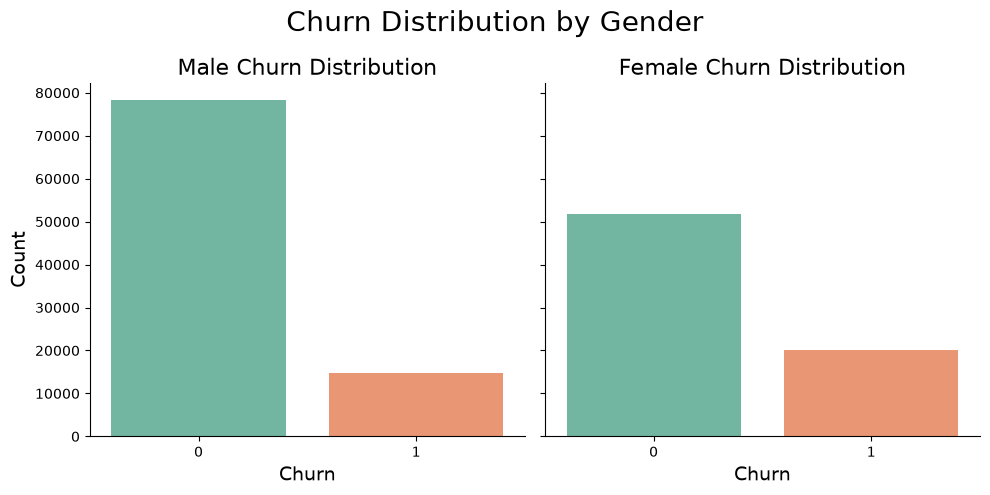

In [8]:
# create a factegrid to visualize churn distribution by gender
g = sns.FacetGrid(train, col='Gender', height=5, aspect=1)
g.map(sns.countplot, 'Exited', palette='Set2')

g.set_titles(col_template = '{col_name} Churn Distribution', size=16)
g.set_axis_labels('Churn', 'Count', size=14)
g.fig.suptitle('Churn Distribution by Gender', size=20)
plt.tight_layout()
plt.show()

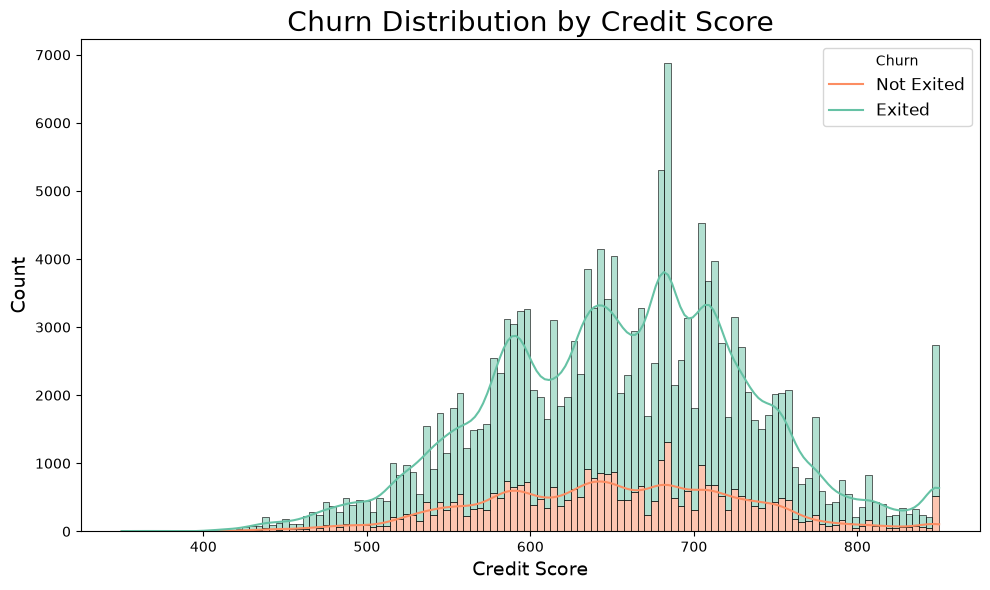

In [9]:
# compare churn for credit score by exited
plt.figure(figsize=(10,6))
sns.histplot(data=train, x='CreditScore', hue='Exited', multiple='stack', palette='Set2', kde=True)
plt.title('Churn Distribution by Credit Score', fontsize=20)
plt.xlabel('Credit Score', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.legend(title='Churn', fontsize=12, labels=['Not Exited', 'Exited'])
plt.tight_layout()

plt.show()

C:\Users\aderinoye stephen\AppData\Local\Temp\ipykernel_27672\4103432939.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train, x='Exited', y=feature, ax=ax, palette='Set2')
C:\Users\aderinoye stephen\AppData\Local\Temp\ipykernel_27672\4103432939.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train, x='Exited', y=feature, ax=ax, palette='Set2')
C:\Users\aderinoye stephen\AppData\Local\Temp\ipykernel_27672\4103432939.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=train, x='Exited', y=feature, ax=ax, palette='Set2'

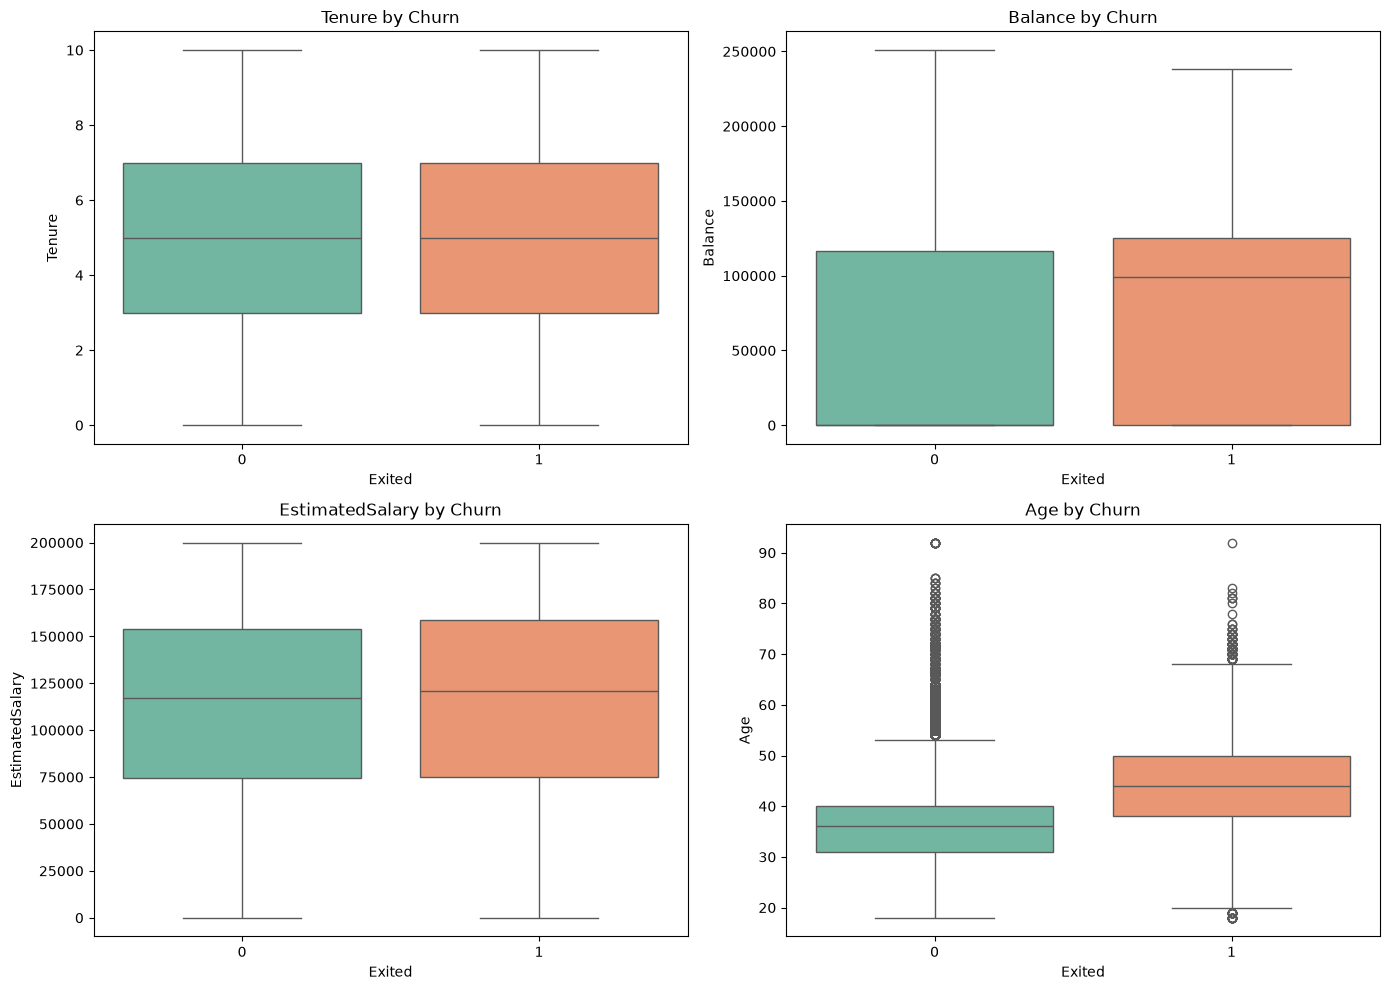

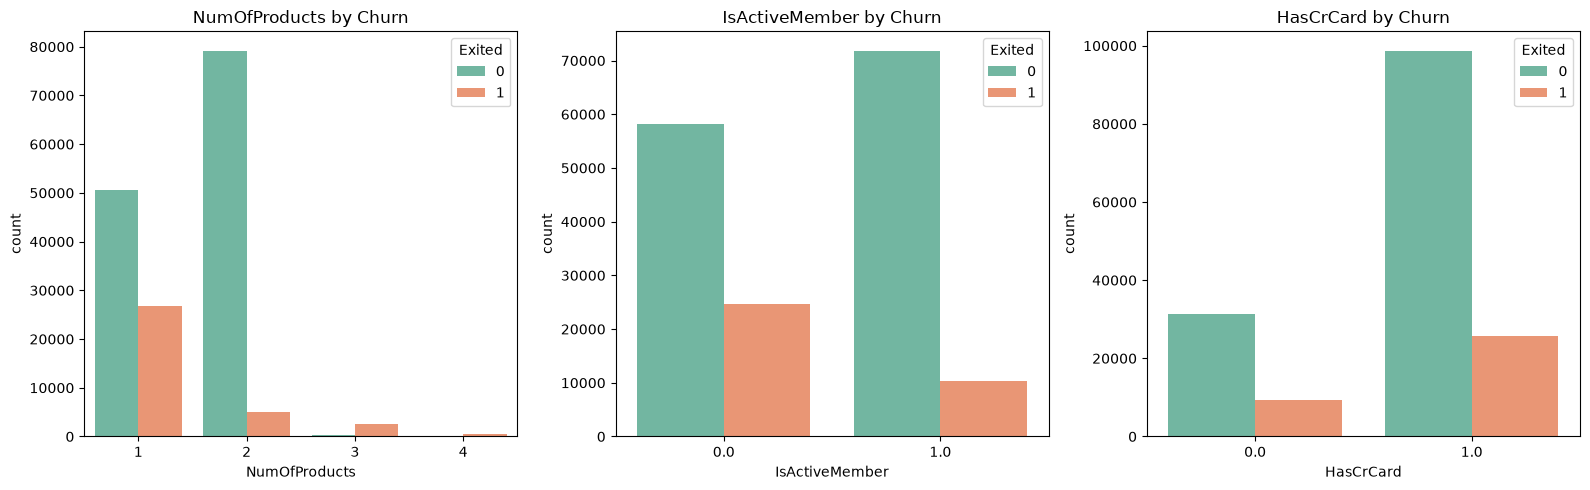

In [10]:
# Plot the remaining numerical features with respect to churn
continuous_features = ['Tenure', 'Balance', 'EstimatedSalary', 'Age']
discrete_features = ['NumOfProducts', 'IsActiveMember', 'HasCrCard']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, feature in zip(axes.flat, continuous_features):
    sns.boxplot(data=train, x='Exited', y=feature, ax=ax, palette='Set2')
    ax.set_title(f'{feature} by Churn')

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, feature in zip(axes, discrete_features):
    sns.countplot(data=train, x=feature, hue='Exited', ax=ax, palette='Set2')
    ax.set_title(f'{feature} by Churn')
    ax.legend(title='Exited')

plt.tight_layout()
plt.show()


In [11]:
train.head()

,id,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,0,15674932,Okwudilichukwu,668,France,Male,33.0,3,0.00,2,1.0,0.0,181449.97,0
1,1,15749177,Okwudiliolisa,627,France,Male,33.0,1,0.00,2,1.0,1.0,49503.50,0
2,2,15694510,Hsueh,678,France,Male,40.0,10,0.00,2,1.0,0.0,184866.69,0
3,3,15741417,Kao,581,France,Male,34.0,2,148882.54,1,1.0,1.0,84560.88,0
4,4,15766172,Chiemenam,716,Spain,Male,33.0,5,0.00,2,1.0,1.0,15068.83,0


In [12]:
# Data preprocessing and feature engineering
# drop irrelevant columns
train.drop(['id', 'CustomerId', 'Surname'], axis=1, inplace=True)
test.drop(['id', 'CustomerId', 'Surname'], axis=1, inplace=True)

C:\Users\aderinoye stephen\AppData\Local\Temp\ipykernel_27672\379427160.py:3: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  train.drop(['id', 'CustomerId', 'Surname'], axis=1, inplace=True)
C:\Users\aderinoye stephen\AppData\Local\Temp\ipykernel_27672\379427160.py:4: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  test.drop(['id', 'CustomerId', 'Surname'], axis=1, inplace=True)


In [13]:
#apply one hot encoding to categorical features
train = pd.get_dummies(train, columns=['Geography'], drop_first=True)
test = pd.get_dummies(test, columns=['Geography'], drop_first=True)

# binary encoding for gender
train['Gender'] = train['Gender'].map({'Male': 1, 'Female': 0})
test['Gender'] = test['Gender'].map({'Male': 1, 'Female': 0})


train.head()

,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain
0,668,1,33.0,3,0.00,2,1.0,0.0,181449.97,0,False,False
1,627,1,33.0,1,0.00,2,1.0,1.0,49503.50,0,False,False
2,678,1,40.0,10,0.00,2,1.0,0.0,184866.69,0,False,False
3,581,1,34.0,2,148882.54,1,1.0,1.0,84560.88,0,False,False
4,716,1,33.0,5,0.00,2,1.0,1.0,15068.83,0,False,True


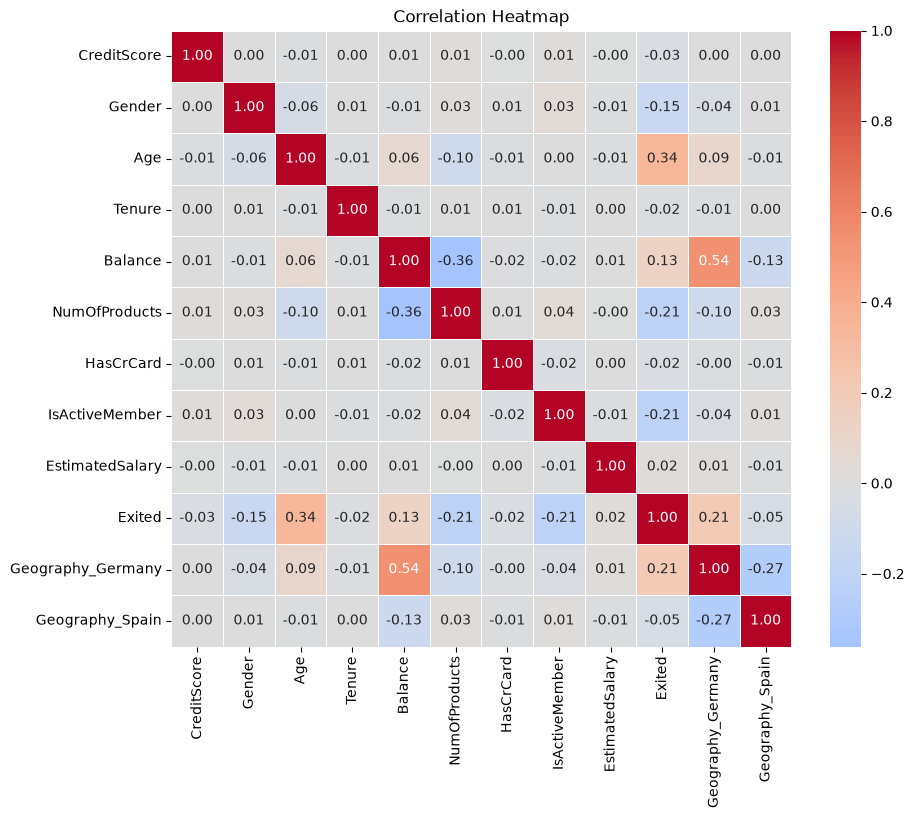

In [14]:
# plot a correlation heatmap to visualize the correlation between features

correlation_matrix = train.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f',linewidths=0.5, linecolor='white', center=0)
plt.title('Correlation Heatmap')
plt.show()  

In [15]:
# seperate features and target variable
X = train.drop('Exited', axis=1)
y = train['Exited']

# split to training and validation sets

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [17]:
from gettext import install
import subprocess


subprocess.run(["pip", "install", "xgboost", "catboost"])

CompletedProcess(args=['pip', 'install', 'xgboost', 'catboost'], returncode=0)

In [18]:
# import histogram-based gradient boosting classifier
from sklearn.ensemble import HistGradientBoostingClassifier

In [19]:
# train on different models and evaluate their performance
models  = {
    "Decision Tree": DecisionTreeClassifier(class_weight='balanced', random_state=42),
    "Random Forest": RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=1),
    "XGBoost": XGBClassifier(scale_pos_weight= (y_train ==0).sum() / (y_train ==1).sum(), eval_metric='logloss', random_state=42),
    "Gradient Boosting": HistGradientBoostingClassifier(class_weight='balanced', random_state=42), 
    "CatBoost": CatBoostClassifier(class_weights=[(y_train==0).sum() / len(y_train),
                                                  (y_train==1).sum() / len(y_train)],
                                                    random_state=42, verbose=0)
                                    
}

In [20]:
from sklearn.metrics import  classification_report, accuracy_score, roc_auc_score, precision_score, recall_score, f1_score, confusion_matrix

In [21]:
# Train and evaluate each model
results = {}
for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_val_scaled)
    y_pred_proba = model.predict_proba(X_val_scaled)[:, 1] if hasattr(model, "predict_proba") else None
    accuracy = accuracy_score(y_val, y_pred)
    roc_auc = roc_auc_score(y_val, y_pred_proba) if y_pred_proba is not None else None
    report = classification_report(y_val, y_pred)

    results[name] = {
        "accuracy": accuracy,
        "roc_auc": roc_auc,
        "classification_report": report
    }

    results_df = pd.DataFrame(
        {
            name: {
                "accuracy": results[name]["accuracy"],
                "roc_auc": results[name]["roc_auc"],
            
            }
            for name in results
        }
    ).T


    print(f"\n{name} Classification Report:\n{report}")
   


Training Decision Tree...

Decision Tree Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.87      0.87     26023
           1       0.53      0.52      0.52      6984

    accuracy                           0.80     33007
   macro avg       0.70      0.70      0.70     33007
weighted avg       0.80      0.80      0.80     33007

Training Random Forest...

Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.90      0.90     26023
           1       0.63      0.66      0.64      6984

    accuracy                           0.85     33007
   macro avg       0.77      0.78      0.77     33007
weighted avg       0.85      0.85      0.85     33007

Training XGBoost...

XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.83      0.88     26023
           1       0.55      0.77      0.64      6984

  

In [22]:
results_df.head()

,accuracy,roc_auc
Decision Tree,0.799739,0.697539
Random Forest,0.846002,0.873047
XGBoost,0.819281,0.886259
Gradient Boosting,0.819250,0.889576
CatBoost,0.845578,0.889407


In [24]:
#hyperparameter tuning for the best performing model (Gradient Boosting Classifier)
from sklearn.model_selection import RandomizedSearchCV

param_distributions = {
    "learning_rate": [0.03, 0.05, 0.08, 0.1],
    "max_iter": [100, 200, 300],
    "max_leaf_nodes": [15, 31, 63],
    "min_samples_leaf": [20, 30, 50],
    "l2_regularization": [0.0, 0.1, 1.0],
}

search = RandomizedSearchCV(
    estimator=HistGradientBoostingClassifier(
        class_weight="balanced",
        random_state=42
    ),
    param_distributions=param_distributions,
    n_iter=15,
    scoring="roc_auc",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

search.fit(X_train_scaled, y_train)

best_gb_model = search.best_estimator_
y_val_proba_gb = best_gb_model.predict_proba(X_val_scaled)[:, 1]
y_val_pred_gb = best_gb_model.predict(X_val_scaled)

print("Best parameters:", search.best_params_)
print("Best cross-validation ROC-AUC:", search.best_score_)
print("Validation ROC-AUC:", roc_auc_score(y_val, y_val_proba_gb))
print(classification_report(y_val, y_val_pred_gb))


Fitting 3 folds for each of 15 candidates, totalling 45 fits
Best parameters: {'min_samples_leaf': 20, 'max_leaf_nodes': 15, 'max_iter': 300, 'learning_rate': 0.03, 'l2_regularization': 0.1}
Best cross-validation ROC-AUC: 0.8885862310150751
Validation ROC-AUC: 0.8895916221613632
              precision    recall  f1-score   support

           0       0.94      0.82      0.88     26023
           1       0.55      0.79      0.65      6984

    accuracy                           0.82     33007
   macro avg       0.74      0.81      0.76     33007
weighted avg       0.85      0.82      0.83     33007

